## update Data:

In [93]:
%reload_ext autoreload
%autoreload 2
import os
import sys

sys.path.append('..')
import math
import random
import shutil
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from tqdm import tqdm

from src.dataset import (
    average_hash,
    build_processed,
    check_no_leakage,
    get_embedding,
    make_imagefolders,
    make_loaders,
    make_train_val_split,
    md5_hash,
    scan_all_images,
)
from src.evaluate import predict_loader, summarize
from src.model import CNNBaseline
from src.train import evaluate, fit, make_scheduler, train_one_epoch
from src.utils import get_device, set_seed

DATA_ROOT='../data/raw/dataset'
os.listdir(DATA_ROOT)

SEED , EPOCHS , IMG_SIZE , BATCH = 42 , 30 , 128 , 32
DATA = '../data/processed'
RESULTS = '../results/experiments.csv'

os.makedirs('../results', exist_ok=True)
os.makedirs('../results/logs', exist_ok=True)
os.makedirs('../checkpoints', exist_ok=True)

print(f"✅ RESULTS = {RESULTS}")
device= get_device()




✅ RESULTS = ../results/experiments.csv


In [12]:
raw = """<214844236> , vanet(removed) , duplicate of unclean/neysan - train copy mislabeled
<203730891> , savari , taxi , wrong class
<206803325> , savari , taxi , wrong class
<2161918324> , taxi , savari , wrong class
<218147453> , taxi , _ , delete , wrong_label
<218268791> , taxi , _ , delete , wrong_label
<216191824> , savari , _ , delete , wrong_label
<217712958>, minibus , _ , delete , unusual
<215722954>, minibus , _ , delete , unusual
<217025806>, minibus , _ , delete , unusual
<205763607>, minibus , _ , delete , unusual
<203677139>, minibus , _ , delete , unusual"""

rows = []
for line in raw.strip().split('\n'):
    parts = [p.strip() for p in line.split(',')]
    filename = parts[0].strip('<>').strip()
    old_class = parts[1].strip()
    
    if len(parts) == 3:
        action, new_class, reason = 'delete', '', parts[2]
    elif len(parts) == 4:
        if parts[2] == '_':
            action, new_class, reason = 'delete', '', parts[3]
        else:
            action, new_class, reason = 'reclassify', parts[2], parts[3]
    elif len(parts) == 5:
        action, new_class, reason = parts[3], '', parts[4]
    else:
        action, new_class, reason = 'unknown', '', ' '.join(parts[2:])
    
    rows.append({
        'filename': filename, 'old_class': old_class,
        'action': action, 'new_class': new_class,
        'reason': reason, 'date': date.today().isoformat(),
    })

df = pd.DataFrame(rows)
df.to_csv('../results/manual_relabel_log.csv', index=False)
print(df.to_string(index=False))
print(f"\n{len(df)} save")

  filename      old_class     action new_class                                              reason       date
 214844236 vanet(removed)     delete           duplicate of unclean/neysan - train copy mislabeled 2026-10-05
 203730891         savari reclassify      taxi                                         wrong class 2026-10-05
 206803325         savari reclassify      taxi                                         wrong class 2026-10-05
2161918324           taxi reclassify    savari                                         wrong class 2026-10-05
 218147453           taxi     delete                                                   wrong_label 2026-10-05
 218268791           taxi     delete                                                   wrong_label 2026-10-05
 216191824         savari     delete                                                   wrong_label 2026-10-05
 217712958        minibus     delete                                                       unusual 2026-10-05
 215722954

### all vanet pic :

Total: 86 images, 4 pages

=== Page 1 / 4 ===


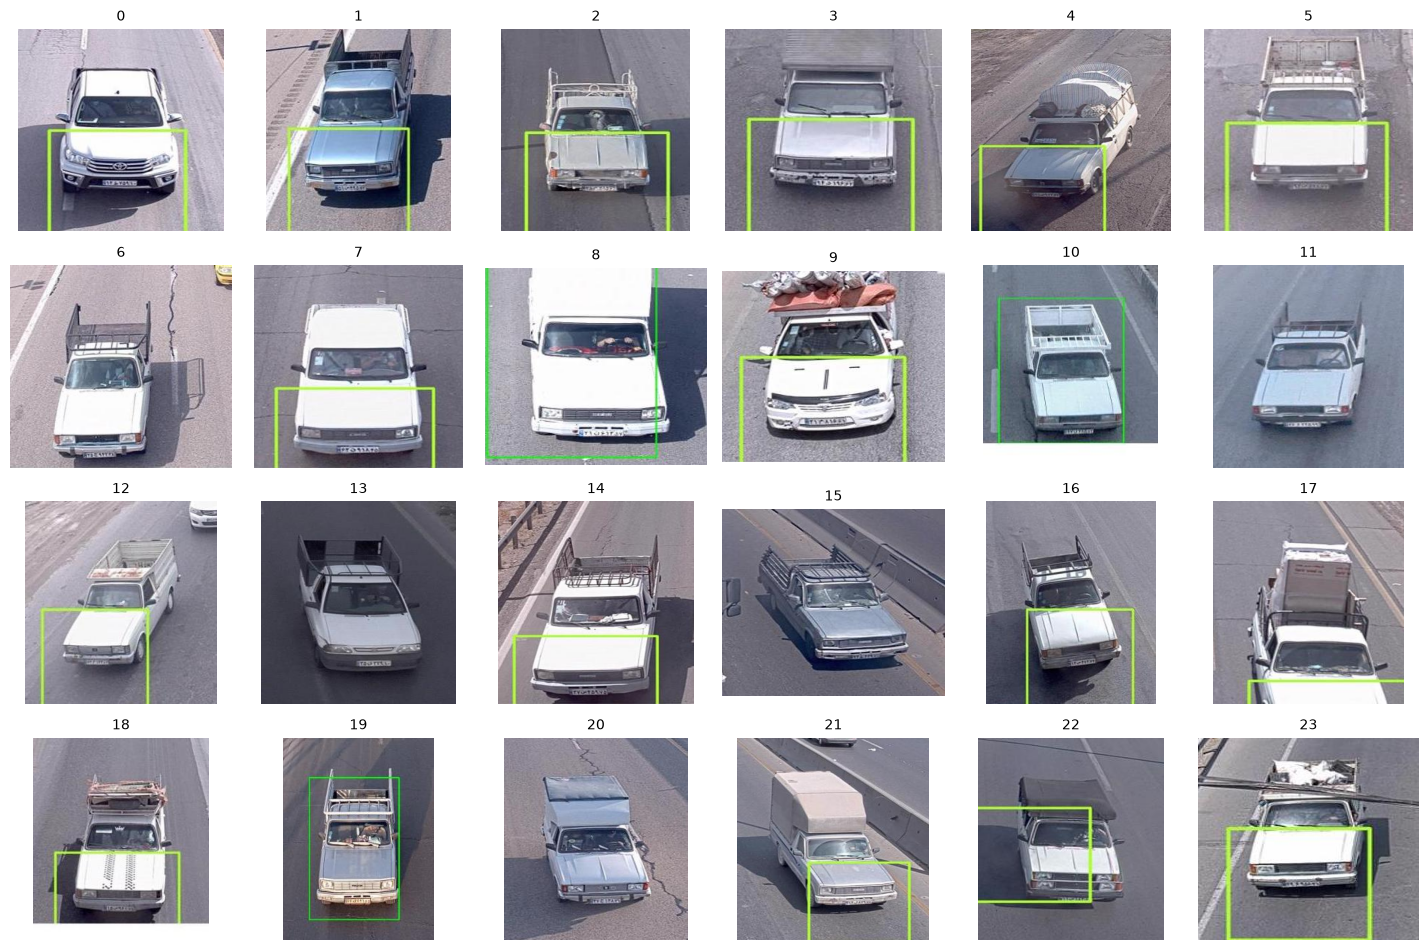

=== Page 2 / 4 ===


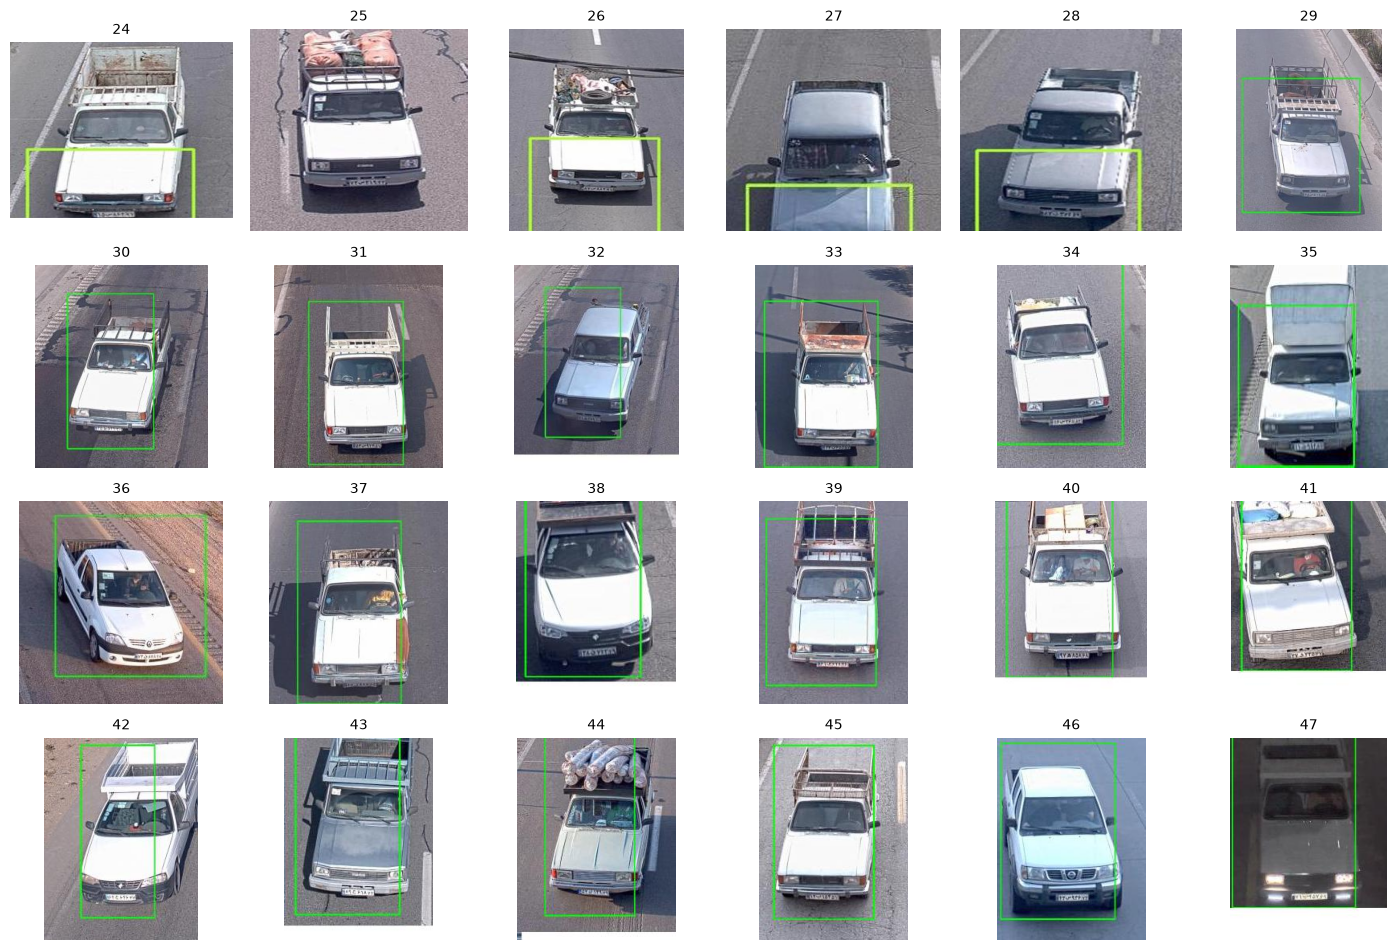

=== Page 3 / 4 ===


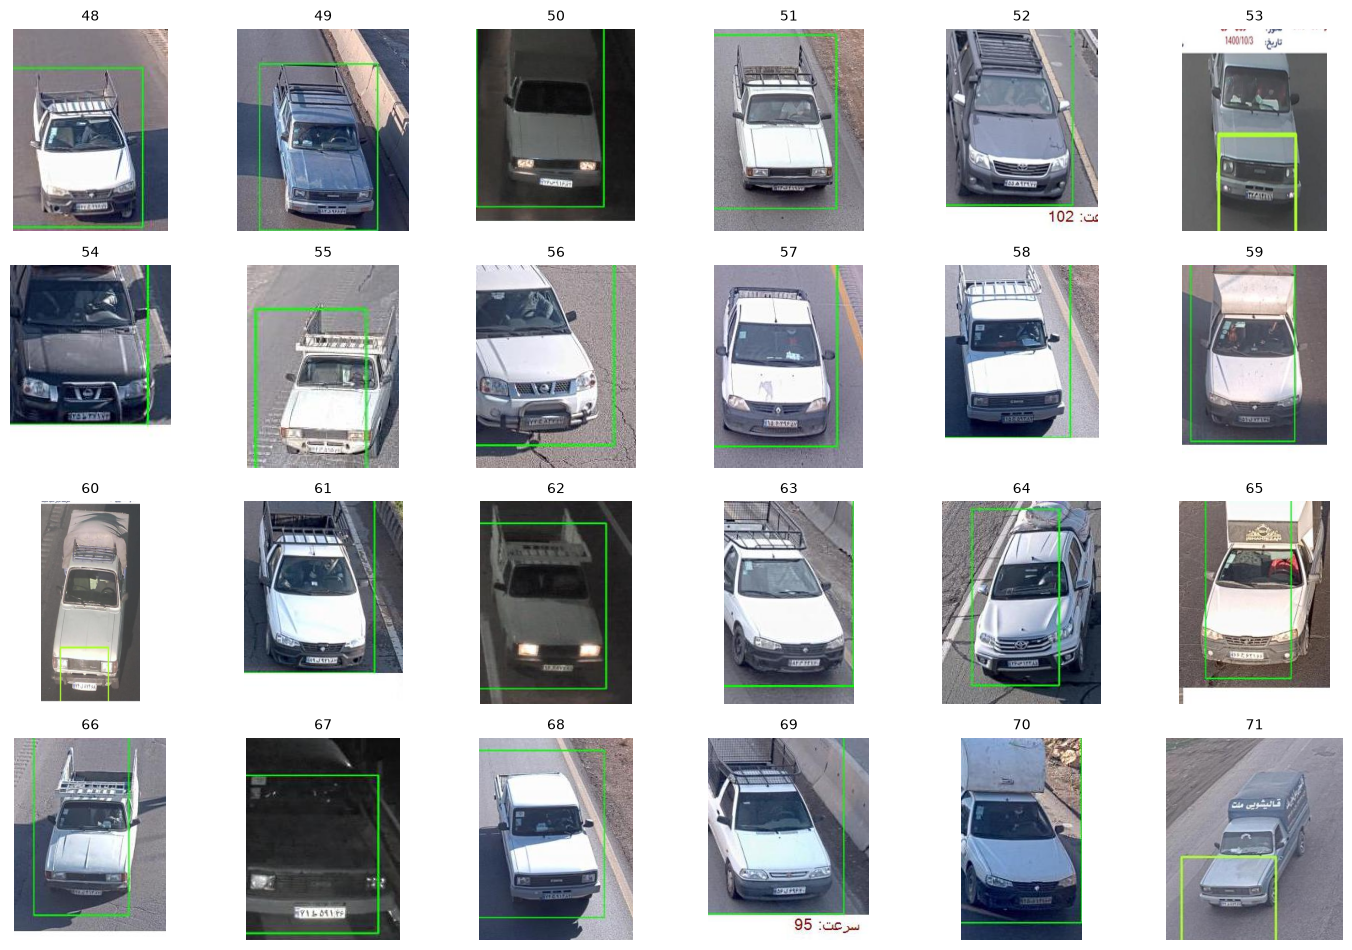

=== Page 4 / 4 ===


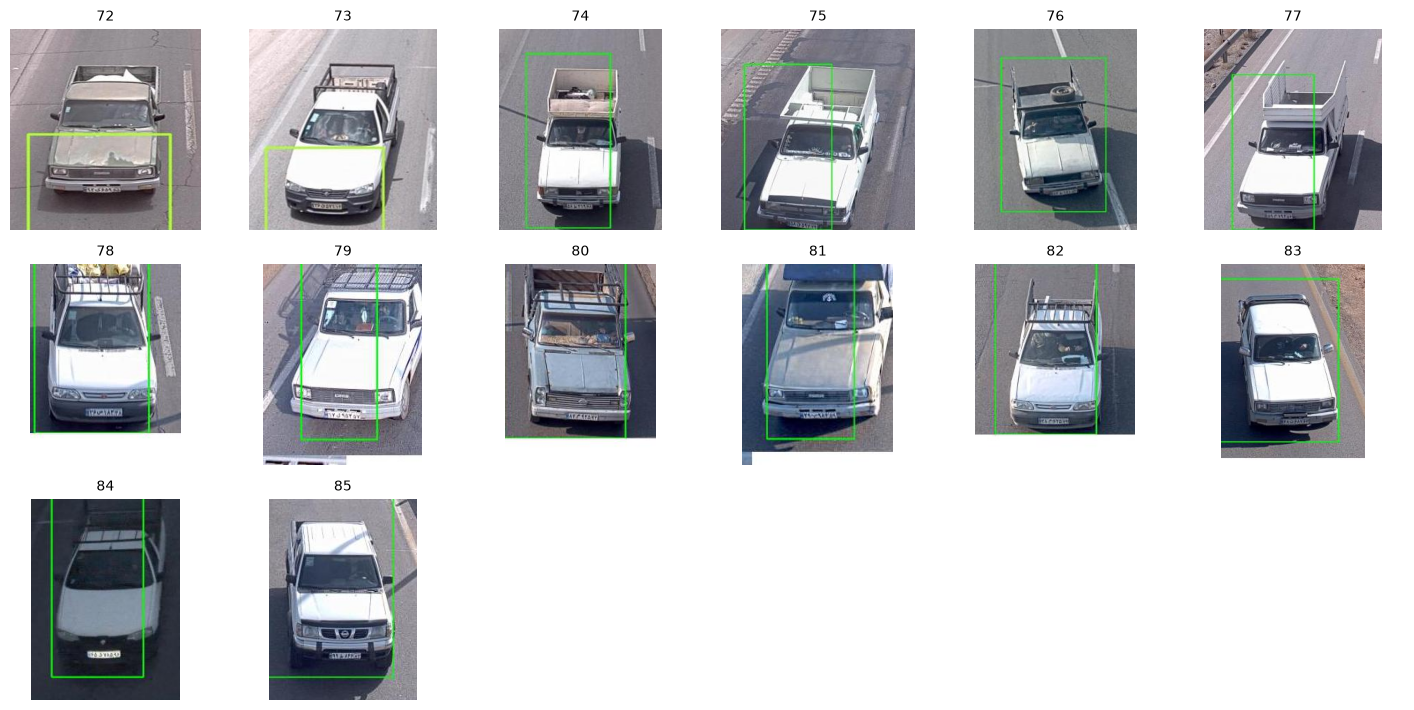

In [90]:
RAW = '../data/raw/dataset'


def list_class_files(split, cls):
    folder = os.path.join(RAW, split, cls)
    return sorted(os.path.join(folder, f) for f in os.listdir(folder))


def show_page(files, page, per_page=24, cols=6):
    chunk = files[page * per_page:(page + 1) * per_page]
    if len(chunk) == 0:
        return
    rows = math.ceil(len(chunk) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.4, rows * 2.4))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis('off')
    for i, (ax, path) in enumerate(zip(axes, chunk)):
        with Image.open(path) as img:
            ax.imshow(img)
        ax.set_title(str(page * per_page + i), fontsize=10)

    plt.tight_layout()
    plt.show()

vanet_files = list_class_files('train', 'vanet') + list_class_files('test', 'vanet')

n = len(vanet_files)
per_page = 24
total_pages = math.ceil(n / per_page)

print(f"Total: {n} images, {total_pages} pages\n")

for p in range(total_pages):
    print(f"=== Page {p + 1} / {total_pages} ===")
    show_page(vanet_files, page=p, per_page=per_page)

In [95]:
nissan_idx = sorted({
    
})

nissan_files = [vanet_files[i] for i in nissan_idx]
NV = os.path.join(RAW, 'neysan_val')
os.makedirs(NV, exist_ok=True)
log_rows = []
skipped = []

for p in nissan_files:
    p = Path(p)
    if not p.exists():
        skipped.append(str(p))
        continue
    
    split, old_cls, fname = p.parts[-3], p.parts[-2], p.name
    shutil.move(str(p), os.path.join(NV, f'{split}__{fname}'))
    
    log_rows.append({
        'filename': fname,
        'old_class': f'{split}/{old_cls}',
        'new_class': 'neysan_val',
        'reason': 'Nissan pickup mislabeled as vanet; moved to unseen-class validation',
        'date': date.today().isoformat(),
    })
log_path = '../results/manual_relabel_log.csv'
new_log = pd.DataFrame(log_rows)
header = not os.path.exists(log_path)
new_log.to_csv(log_path, mode='a', header=header, index=False)

print(f" move: {len(log_rows)}")
print(f" skip : {len(skipped)}")
print(f" neysan_val: {len(os.listdir(NV))}")

 move: 0
 skip : 0
 neysan_val: 210


In [96]:
pd.DataFrame({'filename': sorted(os.listdir(NV))}).to_csv('../data/processed/neysan_val_files.csv', index=False)